In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

El equipo ha dado tres estimaciones de la duración de cada actividad (optimista $a$, más probable $m$ y pesimista $b$, en semanas). Para las actividades E y C se extravió la estimación optimista, pero se conserva la duración media que se había calculado.

In [4]:
pregunta_1 = "1. Calcule la duración media y la varianza de cada actividad según el método PERT.  "
pregunta_2 = "2. Recupere la estimación optimista de E y C a partir de su duración media.  "
pregunta_3 = "3. Dibuje el grafo PERT, determine el camino crítico con las duraciones medias y la duración media del proyecto. ¿Qué papel juegan las estimaciones optimista y pesimista en ese cálculo?  "
pregunta_4 = "4. Para la actividad B, compare la media y la desviación típica que resultan de suponer una distribución Beta-PERT, una triangular y una uniforme con los mismos valores extremos. ¿Cuál es más prudente?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule la duración media y la varianza de cada actividad según el método PERT.  

2. Recupere la estimación optimista de E y C a partir de su duración media.  

3. Dibuje el grafo PERT, determine el camino crítico con las duraciones medias y la duración media del proyecto. ¿Qué papel juegan las estimaciones optimista y pesimista en ese cálculo?  

4. Para la actividad B, compare la media y la desviación típica que resultan de suponer una distribución Beta-PERT, una triangular y una uniforme con los mismos valores extremos. ¿Cuál es más prudente?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, a  , m, b , duration
    ('A'     , '---'      , 3  , 5, 7 , '?'     ),
    ('B'     , '---'      , 5  , 7, 15, '?'     ),
    ('C'     , 'A,B'      , '?', 3, 5 , 3       ),
    ('D'     , 'C'        , 5  , 8, 11, '?'     ),
    ('E'     , 'C'        , '?', 6, 7 , 6       ),
    ('F'     , 'C'        , 5  , 6, 7 , '?'     ),
    ('G'     , 'D,F'      , 5  , 7, 9 , '?'     ),
    ('H'     , 'D,E,F'    , 1  , 6, 11, '?'     ),
], columns=['activity', 'predecessor', 'a', 'm', 'b', 'duration']).set_index('activity')
datos_enunciado

,predecessor,a,m,b,duration
activity,,,,,
A,---,3,5,7,?
B,---,5,7,15,?
C,"A,B",?,3,5,3
D,C,5,8,11,?
E,C,?,6,7,6
F,C,5,6,7,?
G,"D,F",5,7,9,?
H,"D,E,F",1,6,11,?


El proyecto corresponde a la organización de un congreso científico; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Definición del programa y fechas',
    'B': 'Reserva de la sede',
    'C': 'Convocatoria de comunicaciones',
    'D': 'Página web e inscripciones',
    'E': 'Contratación de ponentes invitados',
    'F': 'Revisión de los trabajos recibidos',
    'G': 'Elaboración del programa definitivo',
    'H': 'Contratación de catering y viajes',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Definición del programa y fechas
B,Reserva de la sede
C,Convocatoria de comunicaciones
D,Página web e inscripciones
E,Contratación de ponentes invitados
F,Revisión de los trabajos recibidos
G,Elaboración del programa definitivo
H,Contratación de catering y viajes


# Resolución

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Calcule la duración media y la varianza de cada actividad según el método PERT.  

El método PERT supone que la duración sigue una distribución Beta cuya media y varianza se aproximan por

$$D = \frac{a + 4m + b}{6}, \qquad \sigma^2 = \left(\frac{b - a}{6}\right)^2.$$

In [8]:
datos_proyecto = datos_enunciado.copy()
conocidas = datos_proyecto['a'] != '?'
numericas = datos_proyecto.loc[conocidas, ['a', 'm', 'b']].astype(float)
datos_proyecto.loc[conocidas, 'duration'] = numericas.eval('(a + 4 * m + b) / 6')
datos_proyecto.loc[conocidas, 'variance'] = numericas.eval('((b - a) / 6) ** 2')
datos_proyecto

,predecessor,a,m,b,duration,variance
activity,,,,,,
A,---,3,5,7,5.0,0.444444
B,---,5,7,15,8.0,2.777778
C,"A,B",?,3,5,3,NaN
D,C,5,8,11,8.0,1.000000
E,C,?,6,7,6,NaN
F,C,5,6,7,6.0,0.111111
G,"D,F",5,7,9,7.0,0.444444
H,"D,E,F",1,6,11,6.0,2.777778


In [9]:
#| tbl-cap: "Media y varianza de cada actividad con los números sustituidos"
#| label: tbl-estimacionesPaso
detalle_estimaciones(datos_proyecto[conocidas])

,D = (a + 4m + b)/6,σ² = ((b − a)/6)²
A,(3 + 4·5 + 7)/6 = 5.00,((7 − 3)/6)² = 0.444
B,(5 + 4·7 + 15)/6 = 8.00,((15 − 5)/6)² = 2.778
D,(5 + 4·8 + 11)/6 = 8.00,((11 − 5)/6)² = 1.000
F,(5 + 4·6 + 7)/6 = 6.00,((7 − 5)/6)² = 0.111
G,(5 + 4·7 + 9)/6 = 7.00,((9 − 5)/6)² = 0.444
H,(1 + 4·6 + 11)/6 = 6.00,((11 − 1)/6)² = 2.778


## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Recupere la estimación optimista de E y C a partir de su duración media.  

Despejando en la fórmula de la media: $a = 6D - 4m - b$.

In [11]:
faltan = ~conocidas
datos_proyecto.loc[faltan, 'a'] = (6 * datos_proyecto.loc[faltan, 'duration'].astype(float)
                                   - 4 * datos_proyecto.loc[faltan, 'm'].astype(float)
                                   - datos_proyecto.loc[faltan, 'b'].astype(float))
datos_proyecto[['a', 'm', 'b', 'duration']] = datos_proyecto[['a', 'm', 'b', 'duration']].astype(float)
datos_proyecto['variance'] = datos_proyecto.eval('((b - a) / 6) ** 2')
datos_proyecto['standard_deviation'] = np.sqrt(datos_proyecto['variance'])
datos_proyecto.loc[faltan, ['a', 'm', 'b', 'duration', 'variance']]

,a,m,b,duration,variance
activity,,,,,
C,1.0,3.0,5.0,3.0,0.444444
E,5.0,6.0,7.0,6.0,0.111111


## Apartado 3

In [12]:
display(Markdown(pregunta_3))

3. Dibuje el grafo PERT, determine el camino crítico con las duraciones medias y la duración media del proyecto. ¿Qué papel juegan las estimaciones optimista y pesimista en ese cálculo?  

In [13]:
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
duraciones = datos_proyecto['duration'].round().astype(int)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

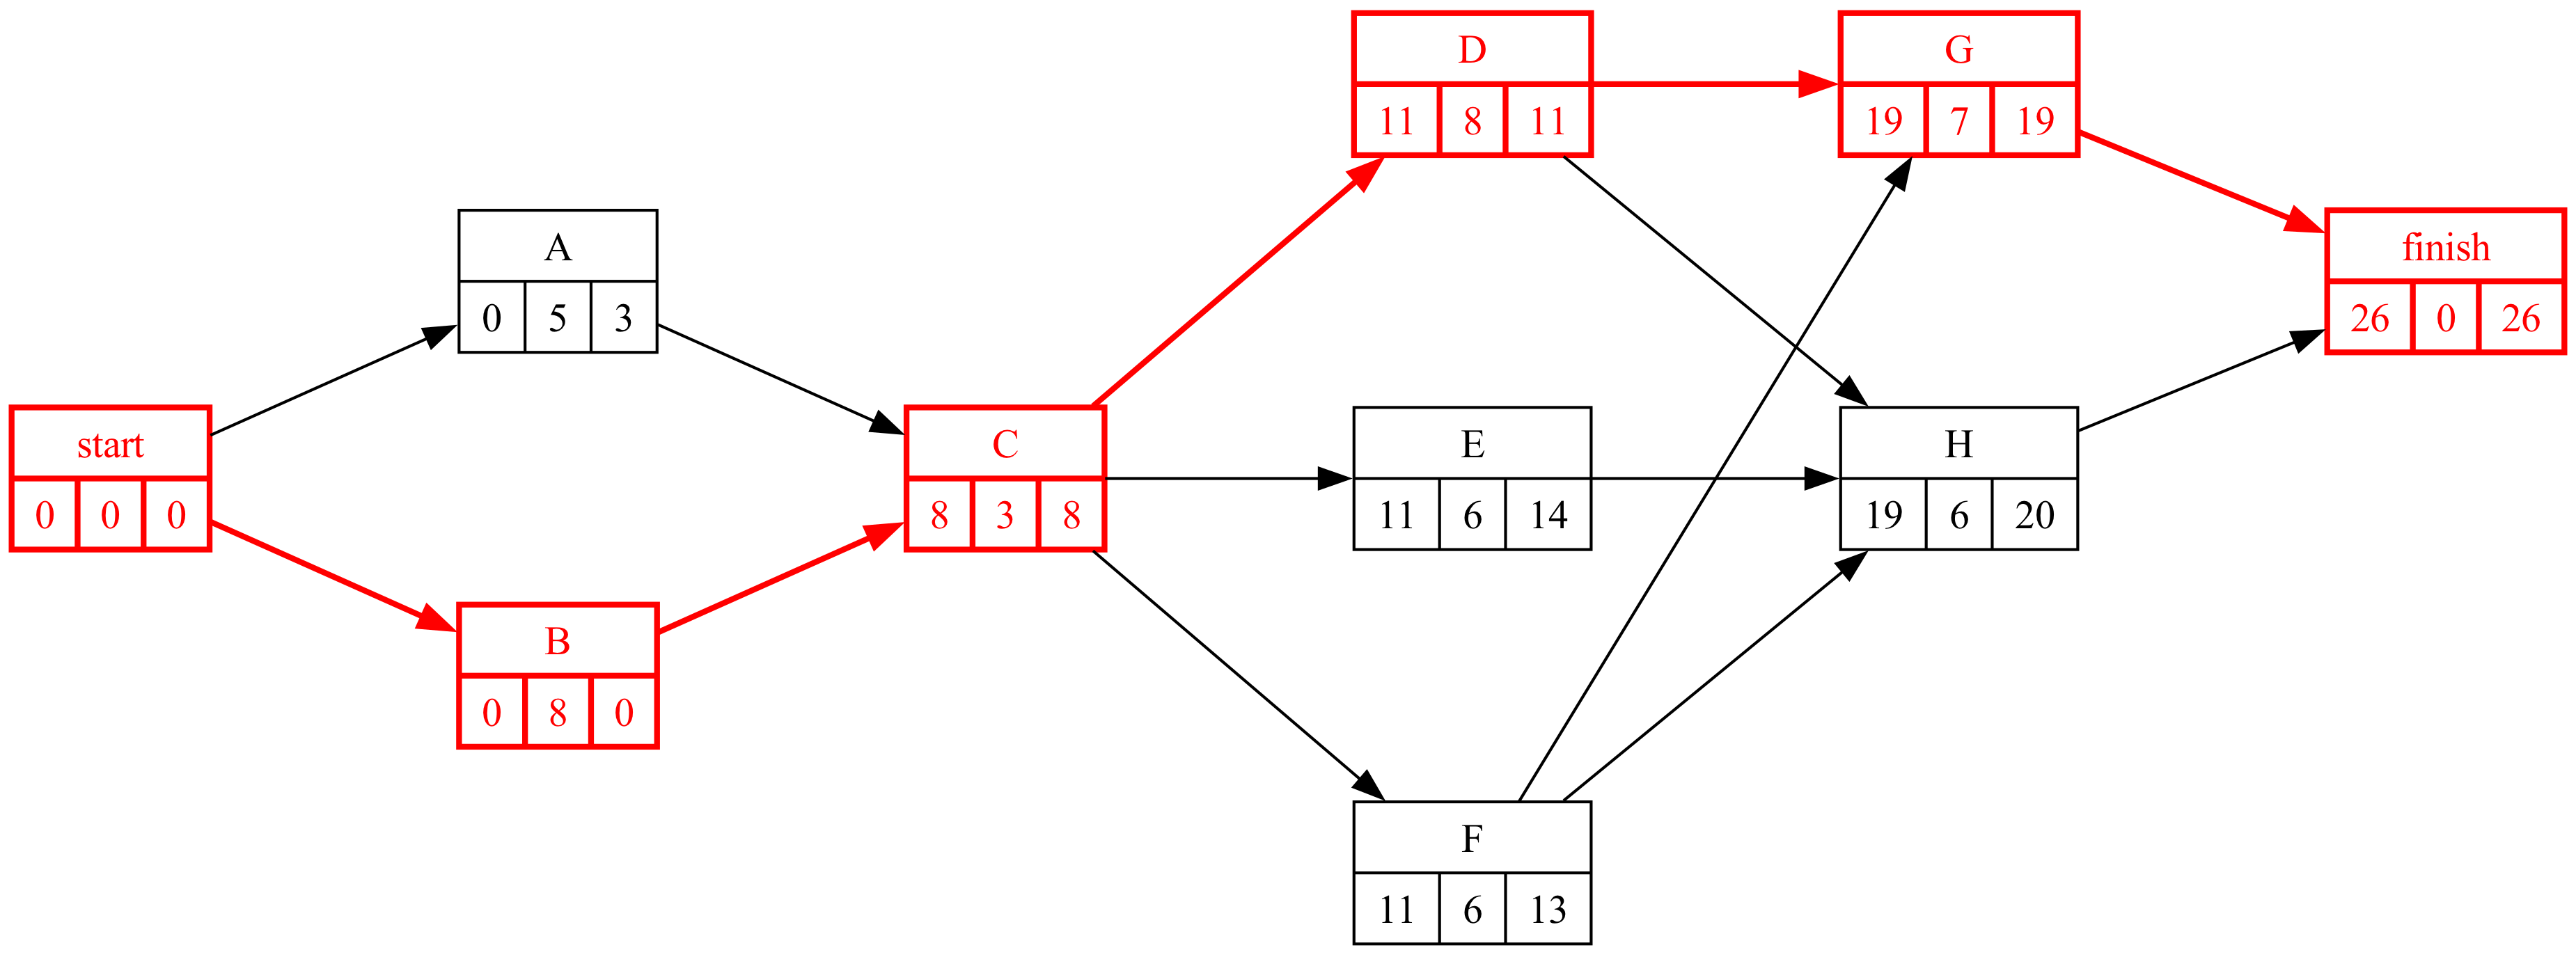

In [14]:
#| fig-cap: "Grafo Roy con las duraciones medias y el camino crítico"
#| label: fig-pert
proyecto.display_roy_pasos(duraciones)

In [15]:
duracion_proyecto = proyecto.duration(duraciones)
camino_critico = proyecto.display_critical_path(duraciones)
Markdown(f'La duración media del proyecto es {duracion_proyecto} semanas. Las estimaciones optimista y pesimista '
         'no intervienen directamente en el camino crítico: sólo a través de la media de cada actividad. '
         'Donde sí cuentan es en la varianza, y por tanto en la probabilidad de cumplir un plazo.')

- Route_6 :	B, C, D, G <br> 

La duración media del proyecto es 26 semanas. Las estimaciones optimista y pesimista no intervienen directamente en el camino crítico: sólo a través de la media de cada actividad. Donde sí cuentan es en la varianza, y por tanto en la probabilidad de cumplir un plazo.

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. Para la actividad B, compare la media y la desviación típica que resultan de suponer una distribución Beta-PERT, una triangular y una uniforme con los mismos valores extremos. ¿Cuál es más prudente?  

Con los mismos extremos $a$ y $b$ (y la misma moda $m$ en la triangular):

| Distribución | Media | Varianza |
|---|---|---|
| Beta-PERT | $(a + 4m + b)/6$ | $((b-a)/6)^2$ |
| Triangular | $(a + m + b)/3$ | $(a^2 + m^2 + b^2 - ab - am - bm)/18$ |
| Uniforme | $(a + b)/2$ | $(b-a)^2/12$ |

In [17]:
a_, m_, b_ = datos_proyecto.loc['B', ['a', 'm', 'b']]
comparacion = pd.DataFrame({
    'Beta-PERT':  [(a_ + 4 * m_ + b_) / 6, ((b_ - a_) / 6) ** 2],
    'Triangular': [(a_ + m_ + b_) / 3, (a_**2 + m_**2 + b_**2 - a_*b_ - a_*m_ - b_*m_) / 18],
    'Uniforme':   [(a_ + b_) / 2, (b_ - a_) ** 2 / 12]},
    index=['media', 'varianza'])
comparacion.loc['desviación típica'] = np.sqrt(comparacion.loc['varianza'])
comparacion.round(3)

,Beta-PERT,Triangular,Uniforme
media,8.000,9.000,10.000
varianza,2.778,4.667,8.333
desviación típica,1.667,2.160,2.887


In [18]:
Markdown(f'''La Beta-PERT concentra la probabilidad cerca de la moda ({m_:.0f}) y por eso tiene la menor varianza; la uniforme reparte la probabilidad por igual entre {a_:.0f} y {b_:.0f} y es la más dispersa; la triangular queda en medio. Cuando la moda no está centrada, las medias también difieren: la PERT pesa la moda cuatro veces y se queda más cerca de ella. La uniforme es la hipótesis más prudente (mayor varianza), pero sólo está justificada si de verdad no se sabe nada entre los extremos.''')

La Beta-PERT concentra la probabilidad cerca de la moda (7) y por eso tiene la menor varianza; la uniforme reparte la probabilidad por igual entre 5 y 15 y es la más dispersa; la triangular queda en medio. Cuando la moda no está centrada, las medias también difieren: la PERT pesa la moda cuatro veces y se queda más cerca de ella. La uniforme es la hipótesis más prudente (mayor varianza), pero sólo está justificada si de verdad no se sabe nada entre los extremos.